In [1]:
import numpy as np
import matplotlib.pyplot as plt
import toolbox as funcs
import sim_funcs as sim
import os
import pickle
import scipy.io
import time

In [13]:
network_params = {"realizations": 200  #(200 originally) small scale realizations  (Critical : should be a large value if large number APs and UEs are used)
                    , "tau_c": 200 # total samples in coherence block
                    , "tau_p": 2  # samples for pilots
                    , "p_k": 200  # uplink max power (mW)
                                     }

area_params = {"delta_h": 10 # height difference
                    , "area": 100  # lxl Service Area
                    , "bandwidth": 100e6
                    , "L": 10  # APs
                    , "N": 2  # antennas per AP
                    , "K": 3  # UEs
                    , "carrier_frequency": 2000  # carrier frequency (MHz)
                    , "sigma_sf_los": 8  # Shadow fading LoS (dB)
                    , "AP_pos_rand": True
                                     }

sim_params = {"setups": 5000,
                     "batch":network_params["realizations"],
                     "v":-1,
                     "d": 0,   #rician factor (0: no LoS component)
                     "norm_type" : np.inf,
                     "tests" :50
                    }

[[0.22915359 0.02656795 0.00770457]
 [0.02436513 0.63052893 0.00411334]
 [0.00657763 0.00088332 0.75103832]]
[[0.22915144 0.0265701  0.00770457]
 [0.02436293 0.63053113 0.00411334]
 [0.00657504 0.00088592 0.75103832]]
[[0.22915144 0.02656795 0.00770672]
 [0.02436293 0.63052893 0.00411554]
 [0.00657504 0.00088332 0.75104092]]
inv Z?:  True 

0


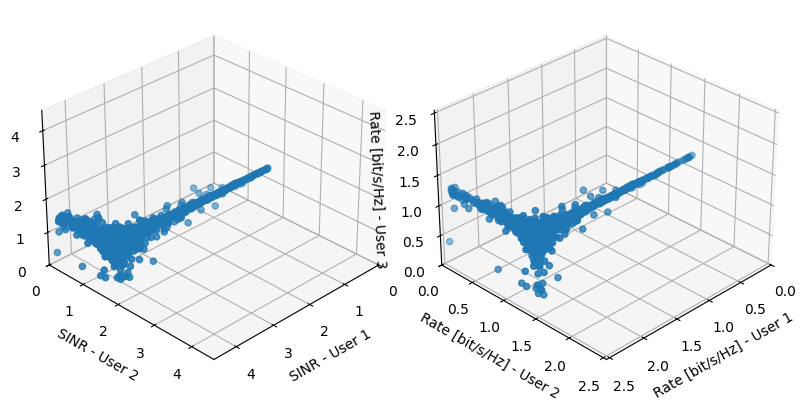

[[0.28807204 0.08015604 0.01754612]
 [0.87824349 0.54152066 0.09183616]
 [0.01410441 0.00913757 0.43881861]]
inv Z?:  False 

1


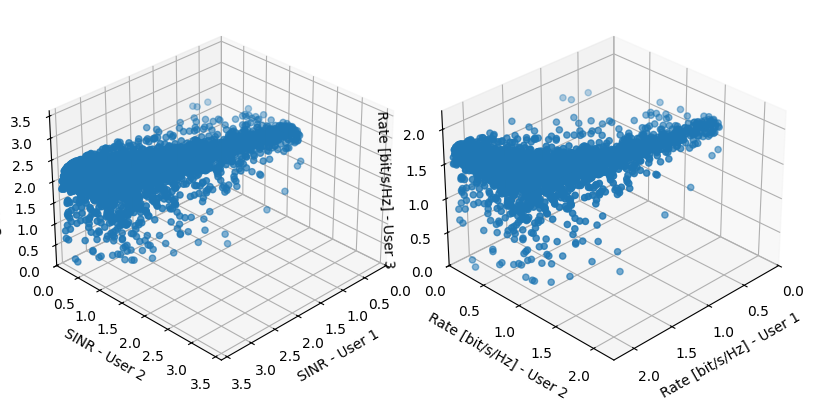

[[0.99846954 0.01989357 0.02038121]
 [0.03882748 0.51114416 0.01852671]
 [0.0454836  0.1727241  0.31723404]]
[[0.99846761 0.0198955  0.02038121]
 [0.03882494 0.51114671 0.01852671]
 [0.0454725  0.17273521 0.31723404]]
[[0.99846761 0.01989357 0.02038315]
 [0.03882494 0.51114416 0.01852926]
 [0.0454725  0.1727241  0.31724514]]
inv Z?:  True 

2


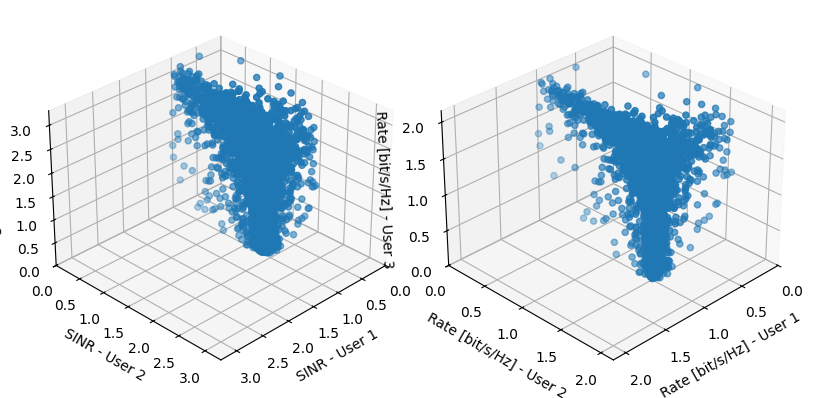

[[0.38742358 0.00403174 0.0467291 ]
 [0.01783345 1.14782663 0.0018371 ]
 [0.29280707 0.02051493 0.28266526]]
inv Z?:  False 

3


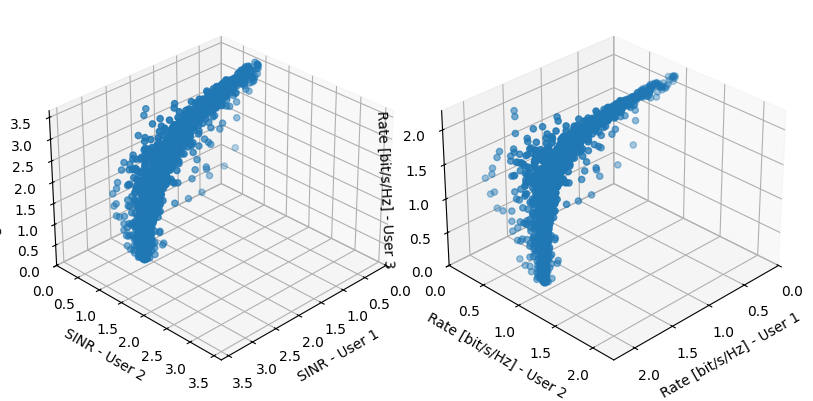

[[0.34818706 0.3426514  0.07414112]
 [0.03222584 0.28940638 0.15118081]
 [0.00854868 0.09279425 0.45355802]]
inv Z?:  False 

4


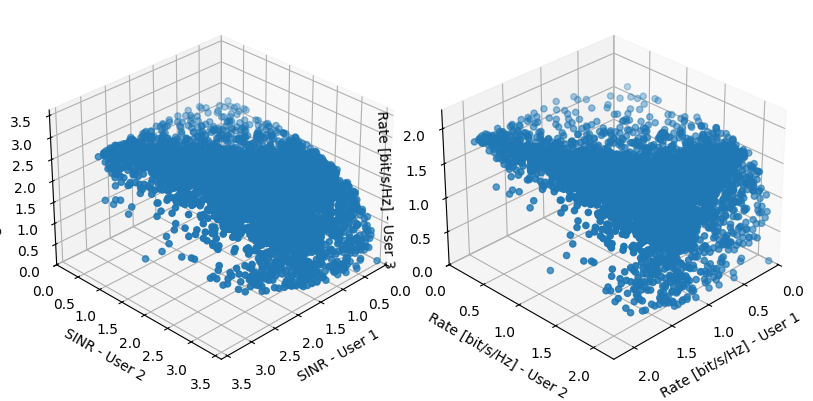

[[0.10984119 0.05881414 0.36682402]
 [0.00262485 0.5486858  0.00383383]
 [0.00105752 0.0174394  0.41250773]]
inv Z?:  False 

5


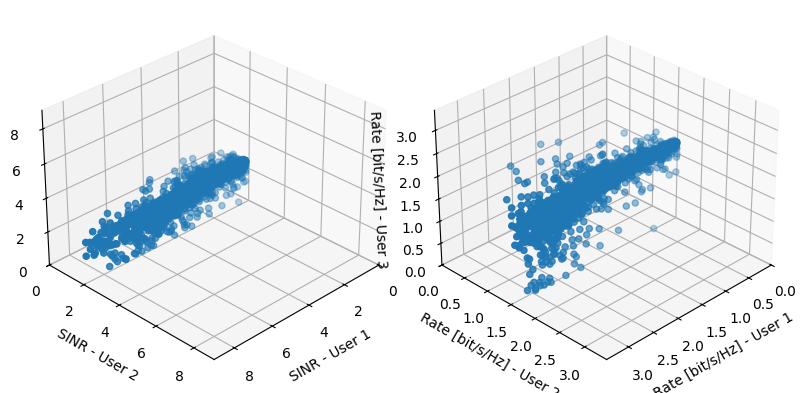

[[3.63986242e-01 3.79735580e-02 1.06755768e-01]
 [2.27376681e-02 2.91835628e-01 5.73339292e-02]
 [4.38018960e-04 1.45704171e-02 5.48187934e-01]]
inv Z?:  False 

6


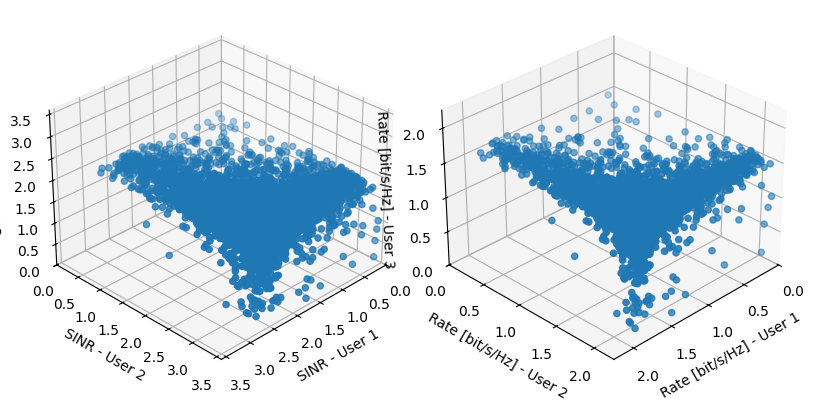

[[0.41071046 0.07519098 0.01385963]
 [0.07552157 0.1876304  0.15305554]
 [0.0062872  0.03852852 0.73423765]]
inv Z?:  False 

7


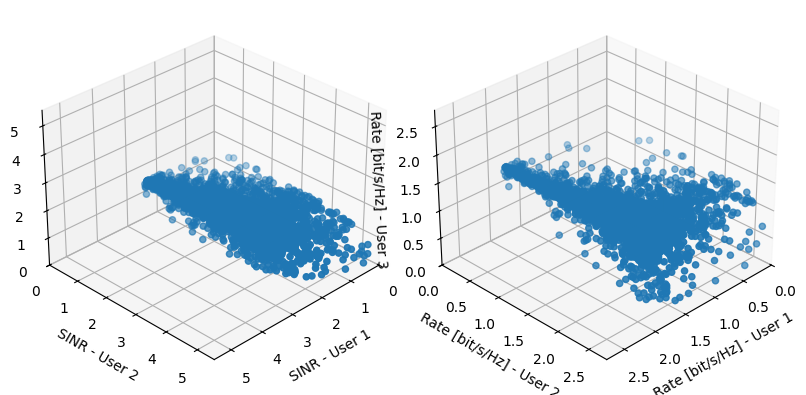

[[0.29522654 0.15932572 0.02677967]
 [0.05325058 0.21233541 0.01199394]
 [0.01719158 0.00809701 0.44013613]]
inv Z?:  False 

8


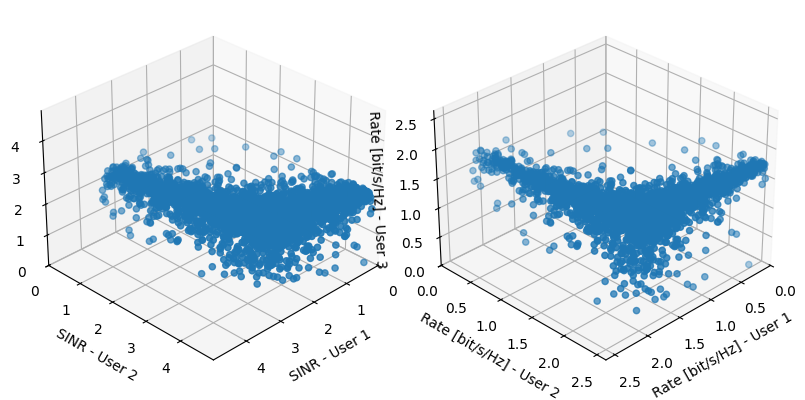

[[0.28733546 0.13858081 0.01548221]
 [0.00546652 0.27680751 0.01351507]
 [0.08405946 0.41703431 0.54692092]]
[[0.28732434 0.13859193 0.01548221]
 [0.00546476 0.27680928 0.01351507]
 [0.08404813 0.41704564 0.54692092]]
[[0.28732434 0.13858081 0.01549333]
 [0.00546476 0.27680751 0.01351684]
 [0.08404813 0.41703431 0.54693225]]
inv Z?:  True 

9


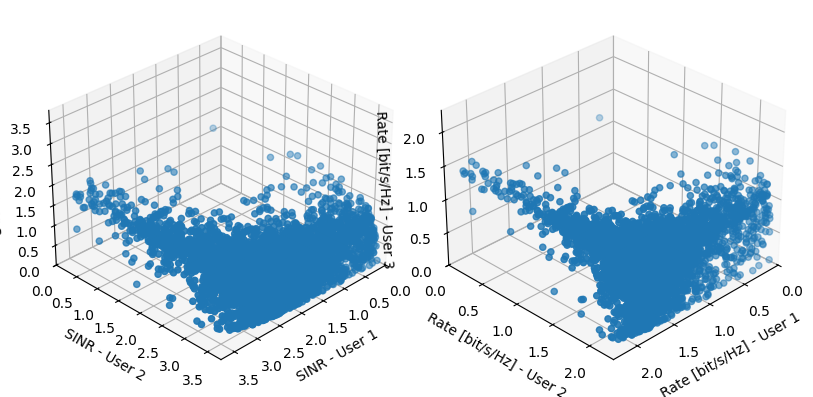

[[0.30494192 0.01397298 0.00393697]
 [0.01014426 0.6079711  0.0088018 ]
 [0.32037314 0.01237604 0.34993588]]
inv Z?:  False 

10


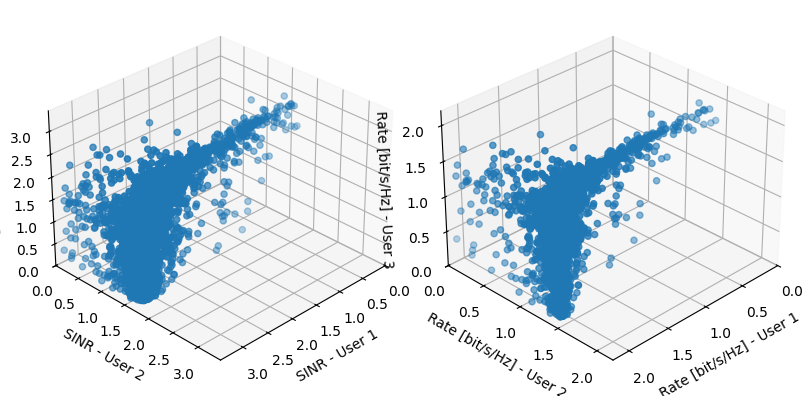

[[0.14404984 0.02716408 0.08959719]
 [0.11011262 0.27718483 0.01652658]
 [0.24738361 0.01945036 0.50205358]]
inv Z?:  False 

11


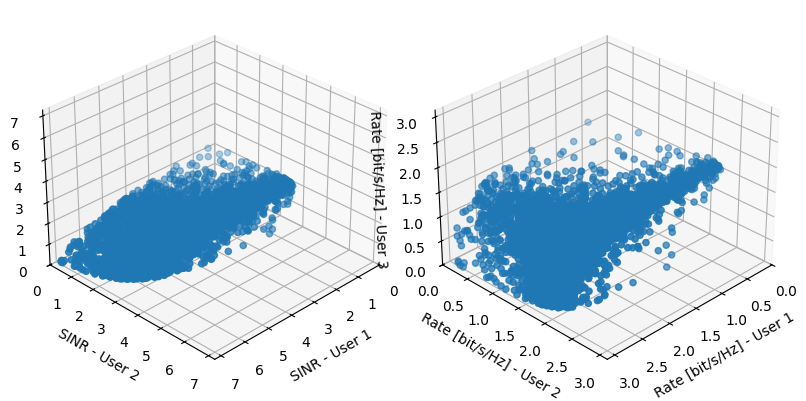

[[0.35072448 0.00544409 0.01293235]
 [0.08406265 0.53134607 0.03097401]
 [0.14709681 0.03595469 0.41572964]]
[[0.35072189 0.00544667 0.01293235]
 [0.08404803 0.53136069 0.03097401]
 [0.14708725 0.03596425 0.41572964]]
[[0.35072189 0.00544409 0.01293494]
 [0.08404803 0.53134607 0.03098863]
 [0.14708725 0.03595469 0.4157392 ]]
inv Z?:  True 

12


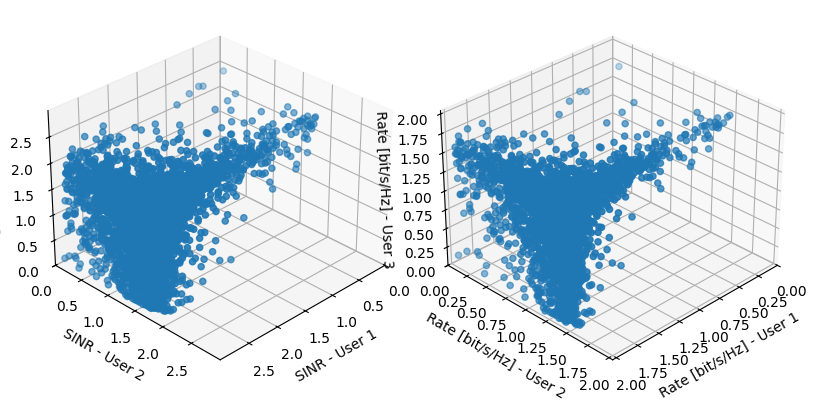

[[4.39500554e-01 8.01768597e-02 4.59851471e-03]
 [4.41376133e-01 4.80650978e-01 6.02150986e-04]
 [7.06394450e-02 1.43223207e-02 6.41818242e-01]]
inv Z?:  False 

13


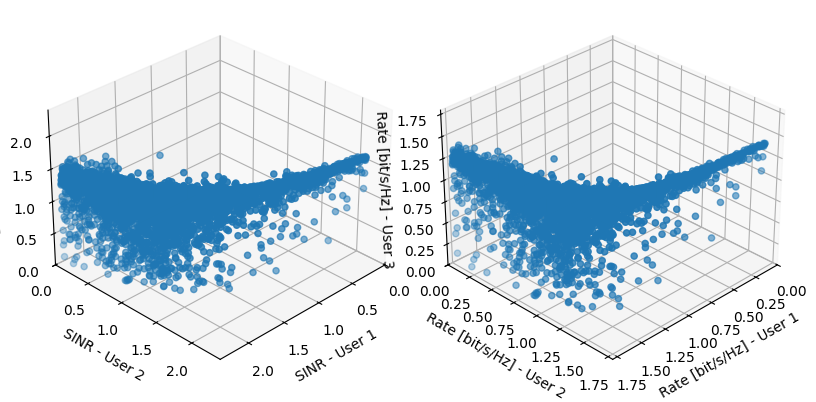

[[6.99644321e-01 2.11277516e-02 2.39714605e-02]
 [7.53832338e+00 5.29067404e-01 9.58435131e-03]
 [1.56959951e-02 9.20356246e-04 8.84200366e-01]]
inv Z?:  False 

14


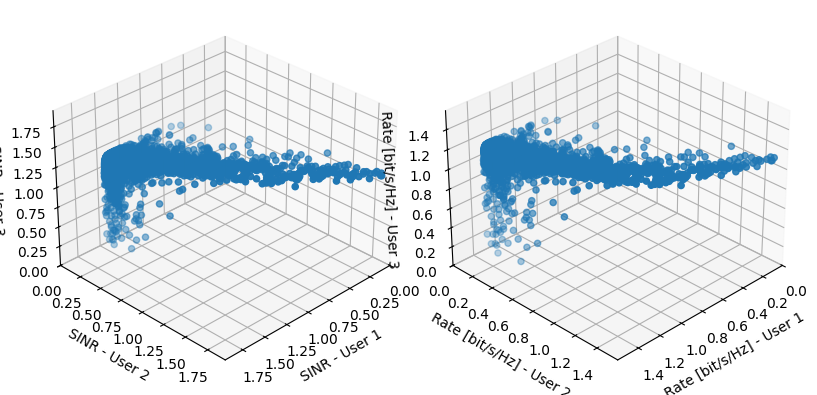

[[0.51781594 0.00084068 0.00725004]
 [0.05267829 0.82002767 0.2112243 ]
 [0.01875952 0.27283345 0.35865468]]
inv Z?:  False 

15


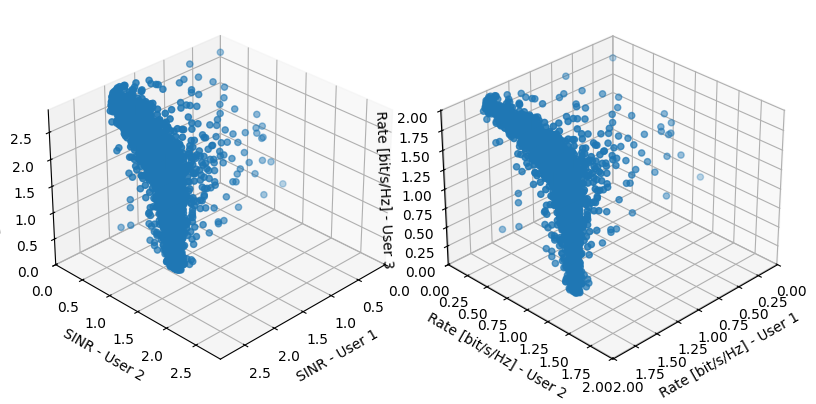

[[4.28886883e-01 3.99334712e-02 2.63244615e-02]
 [4.69815965e-02 2.65677692e-01 1.40467576e+00]
 [4.04592897e-04 8.55610085e-03 6.18868232e-01]]
inv Z?:  False 

16


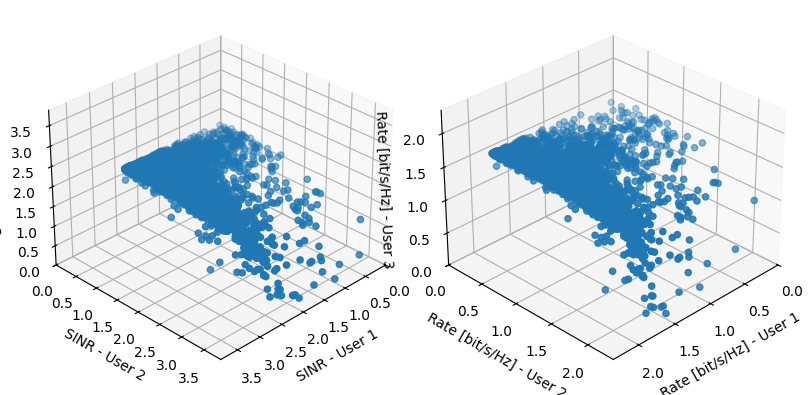

[[5.10154102e-01 1.60109106e-01 7.06708671e-01]
 [1.22865096e-02 3.64608617e-01 4.24184011e-01]
 [1.58108580e-04 1.66234985e-03 7.87195910e-01]]
[[5.10113713e-01 1.60149495e-01 7.06708671e-01]
 [1.22809971e-02 3.64614129e-01 4.24184011e-01]
 [1.57752633e-04 1.66270579e-03 7.87195910e-01]]
[[5.10113713e-01 1.60109106e-01 7.06749060e-01]
 [1.22809971e-02 3.64608617e-01 4.24189523e-01]
 [1.57752633e-04 1.66234985e-03 7.87196266e-01]]
inv Z?:  True 

17


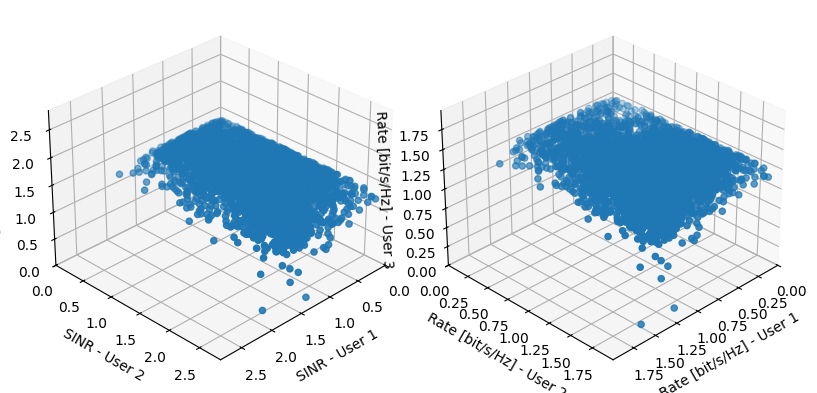

[[0.84486434 0.51685506 0.007875  ]
 [0.02282607 0.27297937 0.23211982]
 [0.00148516 0.02834004 0.65599729]]
inv Z?:  False 

18


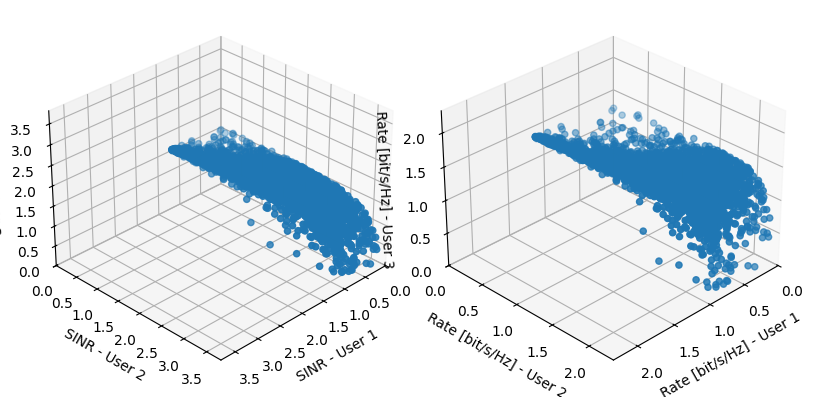

[[0.28846365 0.01824541 0.01870877]
 [0.07315742 0.21486682 0.01743446]
 [0.03427557 0.1861161  0.5038155 ]]
inv Z?:  False 

19


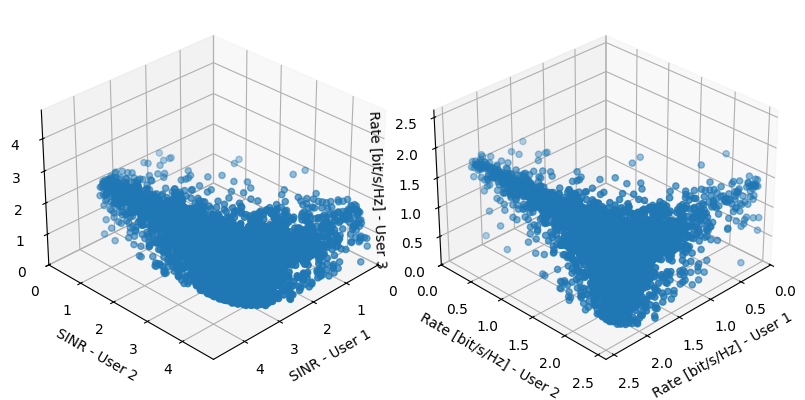

In [14]:
L = area_params["L"]
N = area_params["N"]
K = area_params["K"]
p_max = network_params["p_k"]
filename = f"RateRegions/Areas Sim/results_L{L}N{N}K{K}_rician0.pkl"
area_block = pickle.load(open(filename, "rb"))

for i in range(20):
    inv_interf = True
    (R_block, B_block, HMean_block, kappa_block, UEpos_block, APpos_block) = area_block

    R_spatial_corr_norm = R_block[i,:,:,:,:]
    B_channel_gain =  B_block[i,:,:]
    HMean_norm = HMean_block[i,:,:,:]
    k_rician_factor = kappa_block[i,:,:]
    UEpos = UEpos_block[i,:,:]
    APpos = APpos_block[i,:,:]

    area_values = (R_spatial_corr_norm, B_channel_gain, HMean_norm, k_rician_factor, UEpos, APpos)


    M, u, b, C, sigma, SINR, UEpos, APpos, D_DCC = sim.run_sim(network_params, area_params, sim_params, area_values, i)

    #------------

    p_max = network_params["p_k"]
    K = area_params["K"]

    # A = 1/p_max * np.eye(K)
    A = np.eye(K)
    M_k = np.zeros((K,K,K))
    for k in range(K):
        M_k[k,:,:] = M + (u @ A[:,k][:,np.newaxis].T)/p_max
        # print(M_k[k,:,:])
        if funcs.is_invZ(M_k[k,:,:]) == False:
            inv_interf = False
            break
    print("inv Z?: ", inv_interf, "\n")

    #------------

    # for k in range(K):
    #     print("user",k+1)
    #     print(np.linalg.inv(M_k[k,:,:]), "\n")

    #-----------

    # %matplotlib inline
    # if inv_interf == True:
    if True:
        print(i)
        if K==3:
            x,y,z = SINR
        elif K==2:
            x,y = SINR
        rate_x = np.log2(1+np.array(x) )
        rate_y = np.log2(1+np.array(y) )
        if K==3:
            rate_z = np.log2(1+np.array(z) )

        x_max, y_max = np.max(x), np.max(y)
        max_val = max(x_max, y_max)

        if K==3:
            z_max = np.max(z)
            max_val = max(x_max, y_max, z_max)
        
        rate_x_max, rate_y_max = np.max(rate_x), np.max(rate_y)
        max_rate = max(rate_x_max, rate_y_max)

        if K==3:
            rate_z_max = np.max(rate_z)
            max_rate = max(rate_x_max, rate_y_max, rate_z_max)

            # Create a figure with two 3D subplots
            fig, (ax1, ax2) = plt.subplots(1, 2, subplot_kw={'projection': '3d'}, figsize=(8,4))
            # ax = fig.add_subplot(projection='3d')
            ax1.scatter(x,y,z, linewidths=1)
            ax1.set_xlabel("SINR - User 1", fontsize=10)
            ax1.set_ylabel("SINR - User 2", fontsize=10)
            ax1.set_zlabel("SINR - User 3", fontsize=10)
            ax1.set_xlim([0, max_val + 0.05*max_val])
            ax1.set_ylim([0, max_val + 0.05*max_val])
            ax1.set_zlim([0, max_val + 0.05*max_val])
            ax1.view_init(elev=30, azim=45)  # Set elevation to 30° and azimuth to 45°
            ax2.scatter(rate_x, rate_y, rate_z)
            ax2.set_xlabel("Rate [bit/s/Hz] - User 1", fontsize=10)
            ax2.set_ylabel("Rate [bit/s/Hz] - User 2", fontsize=10)
            ax2.set_zlabel("Rate [bit/s/Hz] - User 3", fontsize=10)
            ax2.set_xlim([0, max_rate + 0.05*max_rate])
            ax2.set_ylim([0, max_rate + 0.05*max_rate])
            ax2.set_zlim([0, max_rate + 0.05*max_rate])
            ax2.view_init(elev=30, azim=45)  # Set elevation to 30° and azimuth to 45°

            #(test)
            # ax1.scatter(0.935980, 2.528388, 1.226463, marker='X', linewidths=1)
            # ax2.scatter(0.660822, 1.261142, 0.800651, marker='X', linewidths=20)
        
        elif K==2:
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8,4))
            ax1.scatter(x,y)

            # ax1.plot([0,max_val], [0,max_val])

            ax1.set_xlabel("SINR - User 1", fontsize=10)
            ax1.set_ylabel("SINR - User 2", fontsize=10)
            ax1.set_xlim([0, max_val + 0.05*max_val])
            ax1.set_ylim([0, max_val + 0.05*max_val])

            ax2.scatter(rate_x, rate_y)

            ax2.set_xlabel("Rate [bit/s/Hz] - User 1", fontsize=10)
            ax2.set_ylabel("Rate [bit/s/Hz] - User 2", fontsize=10)
            ax2.set_xlim([0, max_rate + 0.05*max_rate])
            ax2.set_ylim([0, max_rate + 0.05*max_rate])

            sinr_opt = [2.76824669, 7.66179467]
            ax1.scatter(sinr_opt[0], sinr_opt[1])
            # ax2.plot([0, 2*rate_opt[0]], [0, 2*rate_opt[1]])

            rate_opt = [1.91389342, 3.11466597]
            ax2.scatter(rate_opt[0], rate_opt[1])
            # ax2.plot([0, 2*rate_opt[0]], [0, 2*rate_opt[1]])
        
        plt.tight_layout()
        plt.show()

In [14]:
area_block_1 = pickle.load(open("Areas Sim/results_L20N20K3_rician0.pkl", "rb"))
area_block_2 = pickle.load(open("Areas Sim/results_L20N20K3_rician100.pkl", "rb"))

# print(area_block_1[2] == area_block_2[2])

[[[[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]

  [[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]

  [[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]

  ...

  [[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]

  [[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]

  [[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]]


 [[[ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]
   [ True  True  True ...  True  True  True]]

  [[ True  True  True ...  True 

In [9]:
area_block = sim.create_areas(area_params, sim_params["tests"])

In [166]:
# test_tau = [1,2,3,4,6,8,10,15,20]
test_tau = [3]
results = {}
for tau in test_tau:
    results[tau] = sim.run_test(network_params, area_params, sim_params, area_block, tau)

data = {
    "area_params" : area_params,
    "test_tau" : test_tau,
    "results" : results
}

L = area_params["L"]
N = area_params["N"]
K = area_params["K"]


# filename = f"Results/results_L{L}N{N}K{K}_rician5.pkl"

# with open(filename, "wb") as outfile:
#     pickle.dump(data, outfile)

number of inv Z interf. matrixes: 0


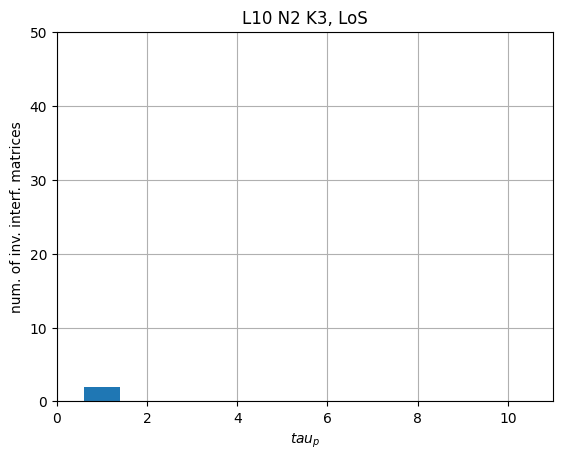

In [55]:
data = pickle.load(open("Results/results_L10N2K3_rician5.pkl", "rb"))
results = data["results"]

plt.bar(results.keys(), results.values())
plt.ylim(0, data["sim_params"["tests"]])
# plt.xlim(0,11)
# plt.yticks(range(0, sim_params["tests"]+1, 1))
# plt.xlabel("$tau_p$")
# plt.ylabel("num. of inv. interf. matrices")
# plt.title("L10 N2 K3, LoS")
plt.grid()
plt.show()
# plt.savefig("plots/L10N2K3_LoS.png")

(0.0, 100.0)

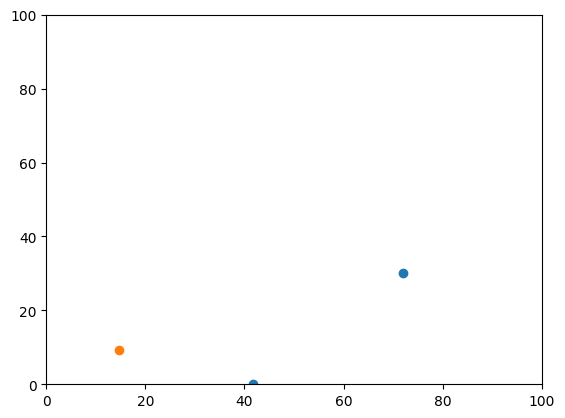

In [107]:
K = area_params["K"]

area = area_params["area"]
fig = plt.figure()
ax = fig.add_subplot()
ax.scatter(np.real(UEpos), np.imag(UEpos))
ax.scatter(np.real(APpos), np.imag(APpos))
ax.set_xlim(0, area)
ax.set_ylim(0, area)